# 20 Newsgroups data

This data set consists of 20000 messages taken from 20 newsgroups: https://archive.ics.uci.edu/dataset/113/twenty+

License: This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license.

In [1]:
# Basic packages
import tarfile
from pathlib import Path
import pandas as pd
import numpy as np
import re

# Visualizations
import matplotlib.pyplot as plt
import seaborn as sns

# NLP packages
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.cluster import KMeans

In [2]:
tar_path = Path("../data/raw/twenty_newsgroups/20_newsgroups.tar.gz")
data_dir = Path("../data/raw/twenty_newsgroups/20_newsgroups")

if not data_dir.exists():
    print("Extracting 20 Newsgroups dataset...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=data_dir.parent)

In [3]:
# Collect each document and its category
documents = []

for category_dir in sorted(data_dir.iterdir()):
    if not category_dir.is_dir():
        continue

    category = category_dir.name

    for file_path in category_dir.iterdir():
        if not file_path.is_file():
            continue

        # Read the text file
        text = file_path.read_text(
            encoding="latin-1",
            errors="replace"
        )

        documents.append({
            "category": category,
            "doc_ID": file_path.name,
            "text": text
        })

df = pd.DataFrame(documents)

print(f"Number of documents: {len(df):,}")
print(f"Number of categories: {df['category'].nunique()}")
df.head()

Number of documents: 19,997
Number of categories: 20


,category,doc_ID,text
0,alt.atheism,53759,Newsgroups: alt.atheism\nPath: cantaloupe.srv....
1,alt.atheism,54127,Newsgroups: alt.atheism\nPath: cantaloupe.srv....
2,alt.atheism,53302,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...
3,alt.atheism,53130,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....
4,alt.atheism,53554,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...


In [4]:
df["text_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
df["line_count"] = df["text"].str.count("\n") + 1
df.head()

,category,doc_ID,text,text_length,word_count,line_count
0,alt.atheism,53759,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,1080,124,29
1,alt.atheism,54127,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,1486,221,40
2,alt.atheism,53302,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,1877,249,50
3,alt.atheism,53130,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,1279,148,27
4,alt.atheism,53554,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,1147,149,26


In [5]:
df[["text_length", "word_count", "line_count"]].describe()

,text_length,word_count,line_count
count,19997.000000,19997.000000,19997.000000
mean,2306.985348,302.378807,50.943091
std,3912.980389,510.959765,80.078355
min,345.000000,21.000000,9.000000
25%,1139.000000,126.000000,27.000000
50%,1600.000000,195.000000,36.000000
75%,2321.000000,314.000000,51.000000
max,161040.000000,11839.000000,2615.000000


In [6]:
headers = [
    "Newsgroups:",
    "Path:",
    "From:",
    "Subject:",
    "Message-ID:",
    "Date:",
    "Organization:",
]

for header in headers:
    count = df["text"].str.contains(
        header,
        regex=False,
        na=False
    ).sum()

    print(f"{header:15} {count:,}")

Newsgroups:     19,997
Path:           19,997
From:           19,997
Subject:        19,997
Message-ID:     19,997
Date:           19,997
Organization:   19,162


In [7]:
# Check the number of documents in each category
df["category"].value_counts().sort_index()

category
alt.atheism                 1000
comp.graphics               1000
comp.os.ms-windows.misc     1000
comp.sys.ibm.pc.hardware    1000
comp.sys.mac.hardware       1000
comp.windows.x              1000
misc.forsale                1000
rec.autos                   1000
rec.motorcycles             1000
rec.sport.baseball          1000
rec.sport.hockey            1000
sci.crypt                   1000
sci.electronics             1000
sci.med                     1000
sci.space                   1000
soc.religion.christian       997
talk.politics.guns          1000
talk.politics.mideast       1000
talk.politics.misc          1000
talk.religion.misc          1000
Name: count, dtype: int64

In [8]:
# Inspect an individual document
print("Category:", df.loc[0, "category"])
print(df.loc[0, "text"][:2000])

Category: alt.atheism
Newsgroups: alt.atheism
Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv.cs.cmu.edu!bb3.andrew.cmu.edu!news.sei.cmu.edu!cis.ohio-state.edu!zaphod.mps.ohio-state.edu!darwin.sura.net!udel!news.intercon.com!psinntp!wrldlnk!usenet
From: "Robert Knowles" <p00261@psilink.com>
Subject: Re: KORESH IS GOD!
In-Reply-To: <930416.141520.7h1.rusnews.w165w@mantis.co.uk>
Message-ID: <2944079995.1.p00261@psilink.com>
Sender: usenet@worldlink.com
Nntp-Posting-Host: 127.0.0.1
Organization: Kupajava, East of Krakatoa
Date: Fri, 16 Apr 1993 23:02:26 GMT
X-Mailer: PSILink-DOS (3.3)
Lines: 15

>DATE:   Fri, 16 Apr 1993 14:15:20 +0100
>FROM:   mathew <mathew@mantis.co.uk>
>
>The latest news seems to be that Koresh will give himself up once he's
>finished writing a sequel to the Bible.
>
>mathew

Writing the Seven Seals or something along those lines.  He's already
written the first of the Seven which was around 30 pages or so and has
handed it over to an assistant for PROOFREADING!.  I wou

In [9]:
# Check for empty / duplicated documents
print("Empty documents:", df["text"].str.strip().eq("").sum())
print("Duplicate documents:", df["text"].duplicated().sum())

Empty documents: 0
Duplicate documents: 531


## Data Cleaning

- Rename categories to more interpretable names; extract top-level prefix for the macro category
- Create functions to clean the text data. 

In [10]:
# Define the mapping for the macro categories
macro_mapping = {
    'alt': 'Religion & Beliefs',
    'comp': 'Computers & Tech',
    'misc': 'Miscellaneous',
    'rec.autos': 'Vehicles',
    'rec.motorcycles': 'Vehicles',
    'rec.sport': 'Sports',
    'sci': 'Science',
    'soc': 'Religion & Beliefs',
    'talk.politics': 'Politics',
    'talk.religion': 'Religion & Beliefs'
}

# Define the specific interpretable names
topic_mapping = {
    'alt.atheism': 'Atheism',
    'comp.graphics': 'Graphics',
    'comp.os.ms-windows.misc': 'MS Windows',
    'comp.sys.ibm.pc.hardware': 'IBM PC Hardware',
    'comp.sys.mac.hardware': 'Mac Hardware',
    'comp.windows.x': 'X Windows',
    'misc.forsale': 'For Sale / Classifieds',
    'rec.autos': 'Automobiles',
    'rec.motorcycles': 'Motorcycles',
    'rec.sport.baseball': 'Baseball',
    'rec.sport.hockey': 'Hockey',
    'sci.crypt': 'Cryptography',
    'sci.electronics': 'Electronics',
    'sci.med': 'Medicine',
    'sci.space': 'Space',
    'soc.religion.christian': 'Christianity',
    'talk.politics.guns': 'Gun Politics',
    'talk.politics.mideast': 'Middle East Politics',
    'talk.politics.misc': 'General Politics',
    'talk.religion.misc': 'General Religion'
}

def get_macro_category(raw_cat):
    if raw_cat.startswith('rec.autos'):
        return macro_mapping['rec.autos']
    elif raw_cat.startswith('rec.motorcycles'):
        return macro_mapping['rec.motorcycles']
    elif raw_cat.startswith('rec.sport'):
        return macro_mapping['rec.sport']
    elif raw_cat.startswith('talk.politics'):
        return macro_mapping['talk.politics']
    elif raw_cat.startswith('talk.religion'):
        return macro_mapping['talk.religion']
    else:
        prefix = raw_cat.split('.')[0]
        return macro_mapping.get(prefix, 'Other')

df['macro_category'] = df['category'].apply(get_macro_category)
df['topic'] = df['category'].map(topic_mapping)

In [11]:
# Headers are everything before the first blank line
def remove_headers(text):
    parts = text.split("\n\n", 1)
    
    if len(parts) == 2:
        return parts[1]
    
    return text

In [12]:
# Remove lines beginning with one or more > or |>
def remove_quoted_lines(text):
    lines = text.splitlines()

    cleaned_lines = []

    for line in lines:
        if line.lstrip().startswith(">") or line.lstrip().startswith("|>"):
            continue

        cleaned_lines.append(line)

    return "\n".join(cleaned_lines)

In [13]:
# Remove common Usenet reply-introduction lines
def remove_reply_introductions(text):
    lines = text.splitlines()

    cleaned_lines = []

    for line in lines:
        if re.match(
            r"^\s*In article .* writes:\s*$",
            line,
            flags=re.IGNORECASE
        ):
            continue

        cleaned_lines.append(line)

    return "\n".join(cleaned_lines)

In [14]:
def clean_newsgroup_post(text):
    text = remove_headers(text)
    text = remove_quoted_lines(text)
    text = remove_reply_introductions(text)

    return text.strip()

In [15]:
df["clean_text"] = df["text"].apply(clean_newsgroup_post)
df.head()

,category,doc_ID,text,text_length,word_count,line_count,macro_category,topic,clean_text
0,alt.atheism,53759,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,1080,124,29,Religion & Beliefs,Atheism,Writing the Seven Seals or something along tho...
1,alt.atheism,54127,Newsgroups: alt.atheism\nPath: cantaloupe.srv....,1486,221,40,Religion & Beliefs,Atheism,"The ""R Us"" thing is trademarked. I don't know..."
2,alt.atheism,53302,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,1877,249,50,Religion & Beliefs,Atheism,"Ad hominem, sarcastic innuendo? Absolutely. ..."
3,alt.atheism,53130,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,1279,148,27,Religion & Beliefs,Atheism,In <1993Apr10.191100.16094@ultb.isc.rit.edu> s...
4,alt.atheism,53554,Path: cantaloupe.srv.cs.cmu.edu!das-news.harva...,1147,149,26,Religion & Beliefs,Atheism,Mark McCullough (mccullou@snake10.cs.wisc.edu)...


In [16]:
print("RAW:")
print(df.loc[0, "text"])

print("\n" + "="*80 + "\n")

print("CLEANED:")
print(df.loc[0, "clean_text"])

RAW:
Newsgroups: alt.atheism
Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv.cs.cmu.edu!bb3.andrew.cmu.edu!news.sei.cmu.edu!cis.ohio-state.edu!zaphod.mps.ohio-state.edu!darwin.sura.net!udel!news.intercon.com!psinntp!wrldlnk!usenet
From: "Robert Knowles" <p00261@psilink.com>
Subject: Re: KORESH IS GOD!
In-Reply-To: <930416.141520.7h1.rusnews.w165w@mantis.co.uk>
Message-ID: <2944079995.1.p00261@psilink.com>
Sender: usenet@worldlink.com
Nntp-Posting-Host: 127.0.0.1
Organization: Kupajava, East of Krakatoa
Date: Fri, 16 Apr 1993 23:02:26 GMT
X-Mailer: PSILink-DOS (3.3)
Lines: 15

>DATE:   Fri, 16 Apr 1993 14:15:20 +0100
>FROM:   mathew <mathew@mantis.co.uk>
>
>The latest news seems to be that Koresh will give himself up once he's
>finished writing a sequel to the Bible.
>
>mathew

Writing the Seven Seals or something along those lines.  He's already
written the first of the Seven which was around 30 pages or so and has
handed it over to an assistant for PROOFREADING!.  I would expect any
dec

### Note on text preprocessing

The raw 20 Newsgroups dataset contains more than just the main content of each discussion post. Posts may include email and Usenet headers, quoted replies, reply indicators, signatures, usernames, email addresses, and other metadata.

For example, a post may contain:

- **Headers:** `From`, `Subject`, `Date`, `Organization`, `Message-ID`, etc.
- **Quoted text:** Previous messages included using `>` or other quotation markers.
- **Reply indicators:** Text such as `In article ..., someone writes:` or `... wrote:`.
- **Signatures:** Author names, email addresses, quotations, and other text appended to the end of a message.
- **Other metadata:** Information about the organization, distribution list, or network through which the message was posted.

There is no single definition of what constitutes "clean" text. **The appropriate preprocessing steps depend on the goal of the analysis.**

For example, if the goal is to classify a post according to its newsgroup, removing headers and quoted replies may be useful because these elements can contain information that reveals the source of the message rather than its actual topic. On the other hand, if the goal were to study how people reply to one another, the quoted text and reply structure could be valuable information and should not necessarily be removed.

Similarly, signatures may be irrelevant for one analysis but useful for another. Aggressively removing names, email addresses, punctuation, or other features could also remove information that is meaningful for a particular task.

Therefore, the preprocessing used in this analysis should be viewed as **one possible approach rather than a universally correct way to clean the dataset**. When working with text data, preprocessing decisions should be made based on the research question and the intended use of the data.

For this analysis, we will create a cleaned version of the text by removing elements that are likely to introduce information unrelated to the content of the discussion, while keeping the original raw text available for comparison.

In [17]:
df["raw_length"] = df["text"].str.len()
df["clean_length"] = df["clean_text"].str.len()

df["percent_removed"] = (
    1 - df["clean_length"] / df["raw_length"]
) * 100

In [18]:
df["percent_removed"].describe()

count    19997.000000
mean        54.848193
std         20.826466
min          0.620321
25%         40.479876
50%         56.581197
75%         70.244238
max        100.000000
Name: percent_removed, dtype: float64

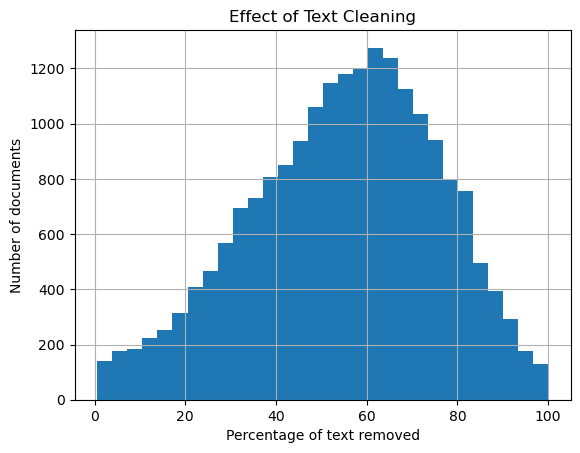

In [19]:
df["percent_removed"].hist(bins=30)

plt.xlabel("Percentage of text removed")
plt.ylabel("Number of documents")
plt.title("Effect of Text Cleaning")
plt.show()

In [20]:
# Inspect 5-10 randomly selected posts to view
for i in df.sample(3, random_state=42).index:
    print("=" * 80)
    print("RAW:")
    print(df.loc[i, "text"][:2000])
    print("\nCLEANED:")
    print(df.loc[i, "clean_text"][:2000])

RAW:
Newsgroups: rec.sport.hockey
Path: cantaloupe.srv.cs.cmu.edu!magnesium.club.cc.cmu.edu!news.sei.cmu.edu!cis.ohio-state.edu!zaphod.mps.ohio-state.edu!cs.utexas.edu!utnut!torn!watserv2.uwaterloo.ca!watserv1!ingo
From: ingo@sunee.uwaterloo.ca (Electroholic)
Subject: Re: Hockey & Hispanic market
Message-ID: <C5sqos.Dn9@watserv1.uwaterloo.ca>
Sender: news@watserv1.uwaterloo.ca
Organization: University of Waterloo
References: <115868@bu.edu>
Distribution: na
Date: Tue, 20 Apr 1993 19:12:28 GMT
Lines: 34

In article <115868@bu.edu> icop@csa.bu.edu (Antonio Pera) writes:
>
>In article <saross01.734885336@starbase.spd.louisville.edu>, saross01@starbase.spd.louisville.edu (Stacey A. Ross) writes:
>|> In <C5I2s2.3Bt@odin.corp.sgi.com> rickc@wrigley.corp.sgi.com (Richard Casares) writes:
>|> >You'll have a hard time selling any sport to a community that
>|> >can't play it on account of availability or financial reasons.
>|> >Hockey is pretty much a sport for the white and well off.
>
>What is

## NLP Preprocessing:

- Lowercase text
- Tokenization
- Remove stopwords
- Handle punctuation
- Stemming / lemmatization
- TF-IDF representation

Will use `nltk` to perform preprocessing. 

### Token-Level Preprocessing (Cleaning & Normalization)
Handles lowercasing, punctuation removal, stopword filtering, and lemmatization. In this case, we will be using lemmatization over stemming because it reduces words to actual dictionary roots rather than truncated fragments, making the intermediate outputs easier to interpret.

- The regex tokenizes by extracting only alphabetic words of 3+ characters, effectively handling punctuation and stripping out noisy 1-2 letter words.

In [21]:
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

tokenizer = RegexpTokenizer(r'\b[a-zA-Z]{3,}\b') 
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    """
    Cleans text by lowercasing, tokenizing, removing stopwords, 
    and applying lemmatization.
    """
    text = str(text).lower()
    
    tokens = tokenizer.tokenize(text)
    
    cleaned_tokens = [
        lemmatizer.lemmatize(word) 
        for word in tokens 
        if word not in stop_words
    ]
    
    return " ".join(cleaned_tokens)

- Show a side-by-side comparison of an example of before and after `preprocess_text()` to demonstrate the importance of cleaning.

In [22]:
sample_idx = df.sample(1, random_state=42).index[0]
original_text = df.loc[sample_idx, "clean_text"]
processed_text = preprocess_text(original_text)

print("BEFORE PREPROCESSING:")
print(original_text[:500] + "..." if len(original_text) > 500 else original_text)

print("\n" + "="*80 + "\n")

print("AFTER PREPROCESSING:")
print(processed_text[:500] + "..." if len(processed_text) > 500 else processed_text)

BEFORE PREPROCESSING:
It's not really crap you know... only half crap ;-)   From what i 
understand it's very expensive to play hockey south of the border... 
(actually it's not that cheap up hear either... though once you have all the
equipement it's not more than $300 a year... actually i haven' played in
about 8 years so i could be off a bit... )  In the states, where ice time
is considerably more expensive it can cost over a thousand a year... compare 
this to baseball and you'll see that hockey is a sport for th...


AFTER PREPROCESSING:
really crap know half crap understand expensive play hockey south border actually cheap hear either though equipement year actually played year could bit state ice time considerably expensive cost thousand year compare baseball see hockey sport well brings fact well majority white btw original question think hispanic communtiy playing hockey cheer ingo sunee uwaterloo violent body iwweigel descartes uwaterloo contact sport ingo electrical watstar 

## Case Study 1: Topic Classification

- Fit a baseline model: Multinomial Naive Bayes.
- Compare the performance of raw vs. cleaned text and evaluate the results using per-class precision, recall, and macro-F1 scores.
- Extract and display the most important features per class by fitting a Naive Bayes model and mapping its log probabilities back to the vectorizer's vocabulary.

### Multinomial Naive Bayes 

#### 1. The Learning Phase (Training)

When we call `fit()`, the model does not actually look at individual documents one by one to build complex rules. Instead, it aggregates everything into a giant lookup table of probabilities.

* **Prior Probability:** It calculates how common each category is overall. (e.g., "5% of all training documents are about Space").
* **Word Probabilities:** For every single word in our 5,000-word TF-IDF vocabulary, it calculates the probability of that word appearing in each of the 20 categories. It learns that words like "orbit" and "moon" have a high probability in the Space category, but a near-zero probability in the Hockey category.

#### 2. The Scoring Phase (Prediction)

When we hand the model a brand new, unseen document, it looks at the words inside that document and calculates a score for each of the 20 categories using Bayes' Theorem.

The formula it uses to score a specific category looks like this:

$$P(\text{Category} \mid \text{Document}) \propto P(\text{Category}) \times \prod_{i=1}^{n} P(\text{Word}_i \mid \text{Category})$$

It means that:

* It starts with the baseline probability of the category: $P(\text{Category})$.
* It multiplies that by the probability of the first word existing in that category: $P(\text{Category}) \times P(\text{Word}_1 \mid \text{Category})$.
* It multiplies *that* by the probability of the second word existing in that category, and so on for every word in the document: $P(\text{Category}) \times \prod_{i=1}^{n} P(\text{Word}_i \mid \text{Category})$.

It does this math for all 20 categories. If a document contains the words "ice", "puck", and "goal", the running multiplication for the Hockey category will stay relatively high. The running multiplication for the Space category will quickly plummet to near zero because the probability of "puck" appearing in Space is incredibly low.

Finally, it lines up the 20 final scores and picks the highest one.

#### Why is it called "Naive"?

The model is considered "naive" because of a massive mathematical assumption: it assumes every word in a document is entirely independent of every other word.

For example, if the model sees the word "San", it assumes that has absolutely no impact on whether the next word is "Francisco". It ignores word order, grammar, and context, treating the document as just a random "bag of words." Despite this naive assumption, it remains incredibly fast and surprisingly accurate for text classification tasks.

### 1. Train-Test Split

- Split the dataset using the `topic` column (80-20 split)

Using `stratify=y` ensures that the proportion of each category in our original dataset is perfectly preserved in both the training and testing sets.

If we were to do a purely random split, we leave the distribution up to chance. Imagine a hypothetical dataset with 1,000 documents where 900 are about "Hockey" and 100 are about "Space". With a purely random 80/20 split, bad luck might dump all 100 "Space" documents into the training set, leaving zero for the test set. Our model would never be evaluated on its ability to classify "Space" documents.

Instead of throwing all the documents into one giant random lottery, `stratify=y` forces the function to look at the `specific_topic` labels first. It groups the data by those labels, creating 20 separate buckets. It then reaches into the "Hockey" bucket and randomly pulls 80% for training and 20% for testing. It repeats this exact process for "Space", "Mac Hardware", and the remaining 17 categories.

This guarantees that the baseline Naive Bayes model will see a representative sample of every single topic during training and will be evaluated fairly on every single topic during testing.

In [23]:
X_raw = df["text"]
X_clean = df["clean_text"]
y = df["topic"]

X_raw_train, X_raw_test, X_clean_train, X_clean_test, y_train, y_test = train_test_split(
    X_raw, X_clean, y, test_size=0.2, random_state=42, stratify=y
)

### 2. Building the Pipelines
- Create two identical pipelines—one for the raw text and one for the cleaned text

**Feature Extraction (TF-IDF Representation)**
Use `scikit-learn` to map the vocabulary and calculate the Term Frequency-Inverse Document Frequency (TF-IDF) scores.

**TF-IDF** is a statistical scoring method used to determine how important a specific word is to a single document within a larger dataset. It works by balancing two different metrics:

- **Term Frequency (TF)**: This counts how many times a word appears in a specific document. The baseline logic is simple: if a document uses the word "space" frequently, the document is likely about space.

- **Inverse Document Frequency (IDF)**: This evaluates how common or rare the word is across the entire dataset (the corpus). Words that appear in almost every document get heavily penalized and their scores are driven toward zero. Words that are rare across the dataset receive a mathematical boost.

When we multiply these two numbers together, the resulting score highlights words that are frequent in a specific post but rare across the whole 20 Newsgroups dataset.

**Parameters**

Use document frequency thresholds (`min_df` and `max_df`) to filter out hyper-rare words like typos and unique names, and ubiquitous words that the stopword list might have missed. 

- `max_features=5000`: Only keep the top 5,000 most frequent words across the dataset and discard the rest. This prevents the model from being overwhelmed by a massive vocabulary, saving memory and processing time.
- `min_df=5` (Minimum Document Frequency): This ignores any word that appears in fewer than 5 documents. It is effective for filtering out typos, unique usernames, or hyper-specific jargon that will not help the model generalize.
- `max_df=0.7`(Maximum Document Frequency): This ignores any word that appears in more than 70% of the documents. It acts as a custom, dataset-specific stopword filter. If a word is used in almost every single post, it carries zero predictive value for separating topics.

In [24]:
# Pipeline 1: Raw Text (Baseline)
raw_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, min_df=5, max_df=0.7)),
    ('clf', MultinomialNB())
])

# Pipeline 2: Cleaned Text
clean_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        preprocessor=preprocess_text,
        max_features=5000, 
        min_df=5, 
        max_df=0.7
    )),
    ('clf', MultinomialNB())
])

# Fit both models 
raw_pipeline.fit(X_raw_train, y_train)
clean_pipeline.fit(X_clean_train, y_train)

# Generate predictions
y_pred_raw = raw_pipeline.predict(X_raw_test)
y_pred_clean = clean_pipeline.predict(X_clean_test)

### 3. Evaluation: Metrics and Confusion Matrix
- Use `classification_report` to generate the per-class precision, recall, and macro-F1 scores. 
- Visualize the confusion matrix to illustrate the macro-categories (e.g., showing how often "IBM PC Hardware" is confused with "Mac Hardware").

In [25]:
print("--- RAW TEXT MODEL PERFORMANCE ---")
print(classification_report(y_test, y_pred_raw))

print("\n--- CLEANED TEXT MODEL PERFORMANCE ---")
print(classification_report(y_test, y_pred_clean))

--- RAW TEXT MODEL PERFORMANCE ---
                        precision    recall  f1-score   support

               Atheism       0.76      0.83      0.79       200
           Automobiles       0.89      0.92      0.90       200
              Baseball       0.98      0.93      0.95       200
          Christianity       0.89      1.00      0.94       200
          Cryptography       0.95      0.96      0.96       200
           Electronics       0.92      0.83      0.87       200
For Sale / Classifieds       0.88      0.91      0.90       200
      General Politics       0.80      0.78      0.79       200
      General Religion       0.69      0.49      0.58       200
              Graphics       0.82      0.81      0.82       200
          Gun Politics       0.84      0.91      0.88       200
                Hockey       0.89      0.95      0.92       200
       IBM PC Hardware       0.86      0.86      0.86       200
            MS Windows       0.90      0.90      0.90       200
    

**Confusion matrix for the cleaned model**

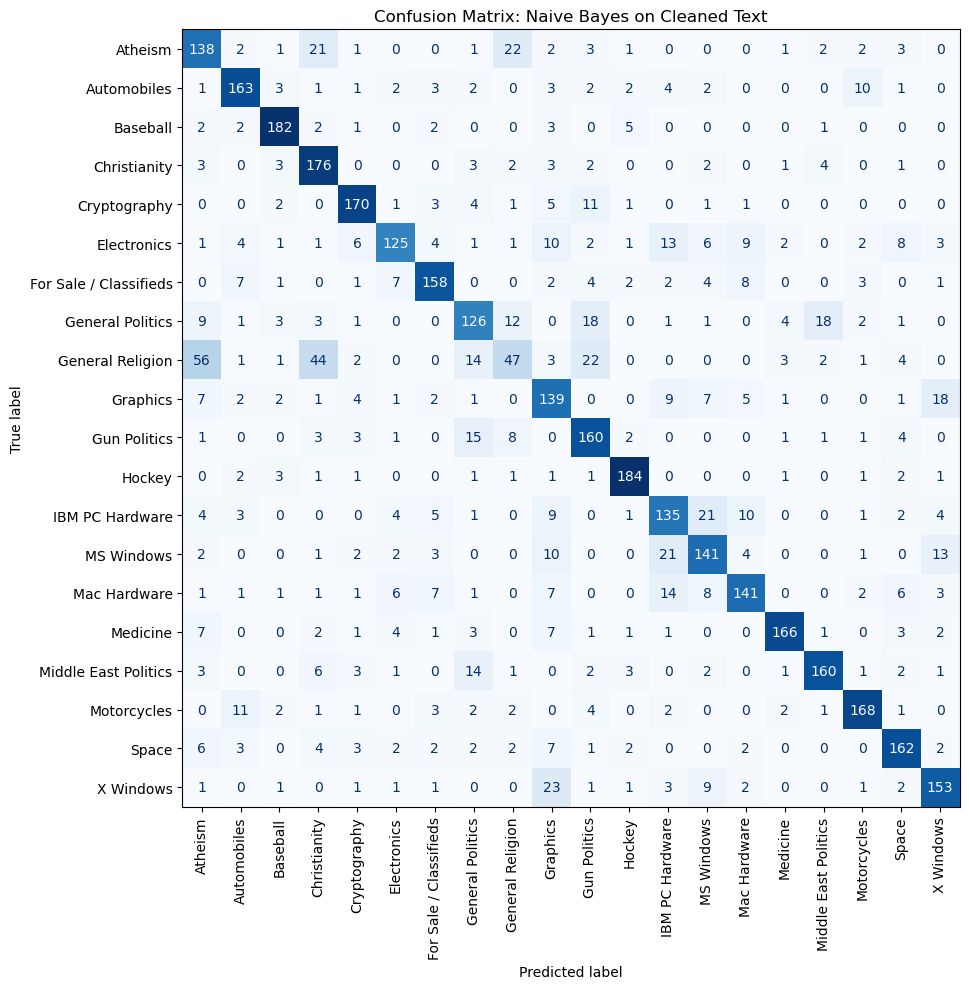

In [26]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_clean, 
    ax=ax, 
    xticks_rotation='vertical',
    cmap='Blues',
    colorbar=False
)
plt.title("Confusion Matrix: Naive Bayes on Cleaned Text")
plt.tight_layout()
plt.show()

**Discussion**

The matrix exposes significant misclassification clusters where conceptually adjacent topics bleed into one another. The most prominent example is the heavy overlap between `General Religion`, `Christianity`, and `Atheism`.

Because Naive Bayes relies on a "bag-of-words" approach, it calculates probabilities based purely on individual word frequencies, completely ignoring word order, tone, and context. These three categories frequently share the exact same root vocabulary—words like "God," "faith," "moral," and "church." The model recognizes the presence of these words but cannot comprehend the philosophical sentiment behind them, making it nearly impossible to consistently separate a theological debate from an atheistic critique. Similar blending occurs between `IBM PC Hardware` and `Mac Hardware`, demonstrating that when domains share a core technical vocabulary, simple frequency-based models will struggle to draw precise boundaries.

### 4. Feature Importance (optional?)

In [27]:
# Extract the fitted vectorizer and classifier from the pipeline
fitted_vectorizer = clean_pipeline.named_steps['tfidf']
fitted_nb = clean_pipeline.named_steps['clf']

feature_names = fitted_vectorizer.get_feature_names_out()

# Select a few distinct categories to showcase using the new specific topics
target_categories = ['Space', 'Automobiles', 'Gun Politics']

for category in target_categories:
    class_idx = list(fitted_nb.classes_).index(category)
    
    # Find the top 10 most influential features
    top_feature_indices = np.argsort(fitted_nb.feature_log_prob_[class_idx])[-10:]
    
    top_features = [feature_names[i] for i in top_feature_indices][::-1]
    
    print(f"Category: {category}")
    print(f"Top features: {', '.join(top_features)}\n")

Category: Space
Top features: space, nasa, edu, henry, would, orbit, like, moon, pat, shuttle

Category: Automobiles
Top features: car, engine, com, edu, like, one, new, would, get, ford

Category: Gun Politics
Top features: gun, com, edu, government, fbi, would, people, fire, weapon, cdt



## Case Study 2: Unsupervised Clustering
- Apply K-Means clustering using the exact same cleaned text and TF-IDF matrix.
- Extract and examine the most representative terms in each cluster.
- Compare the discovered clusters against the original newsgroup labels (both macro and specific).
- Discuss why the discovered clusters might not match the predefined categories, and how unsupervised clustering may be able to handle the overlapping vocabularies identified in Part 1.

### 1. TF-IDF Vectorization and K-Means Execution
Unlike supervised learning where the model is trained on labelled subsets, unsupervised clustering explores the inherent structure of the entire dataset. We will fit the `TfidfVectorizer` on the complete corpus and apply K-Means clustering. 

**Parameters**

- `n_clusters=20`: We set this to 20 to mirror the original number of newsgroups.
- `random_state=42`: This ensures that we get the exact same cluster assignments every time we run it, making the case study completely reproducible.
- `n_init=10`: K-Means begins by dropping random "center" points (centroids) into the data. Because a bad random starting position can lead to poor groupings, this tells the algorithm to try 10 separate times with different starting points and keep the most optimal result.

In [28]:
tfidf_vectorizer = TfidfVectorizer(
    preprocessor=preprocess_text,
    max_features=5000, 
    min_df=5, 
    max_df=0.7
)

X_tfidf_full = tfidf_vectorizer.fit_transform(df["clean_text"])

kmeans = KMeans(n_clusters=20, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_tfidf_full)

print(f"Clustering complete. Assigned {len(df)} documents to {len(kmeans.cluster_centers_)} clusters.")

Clustering complete. Assigned 19997 documents to 20 clusters.


### 2. Extracting Representative Terms per Cluster
To understand what mathematical relationships K-Means found, we extract the highest-weighted TF-IDF features (words) closest to each cluster's centroid.

In [29]:
# Extract feature names from the vectorizer
feature_names = tfidf_vectorizer.get_feature_names_out()

# Get the centroids and sort their feature indices in descending order
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]

print("Top 10 terms per K-Means Cluster:\n" + "="*50)
for i in range(len(kmeans.cluster_centers_)):
    top_terms = [feature_names[ind] for ind in order_centroids[i, :10]]
    print(f"Cluster {i:02d}: {', '.join(top_terms)}")

Top 10 terms per K-Means Cluster:
Cluster 00: edu, writes, article, university, uiuc, say, david, com, would, internet
Cluster 01: one, like, would, get, know, think, time, com, year, say
Cluster 02: space, nasa, gov, shuttle, mission, orbit, launch, would, jpl, satellite
Cluster 03: game, team, player, year, hockey, season, play, win, fan, last
Cluster 04: thanks, please, anyone, mail, know, advance, would, email, looking, edu
Cluster 05: file, format, image, program, window, ftp, directory, gif, edu, convert
Cluster 06: com, writes, article, stratus, netcom, cdt, ibm, one, att, compuserve
Cluster 07: card, driver, video, bus, monitor, ati, window, vga, thanks, color
Cluster 08: use, problem, system, work, one, would, computer, monitor, mac, get
Cluster 09: people, gun, would, government, right, one, law, think, fbi, like
Cluster 10: israel, arab, jew, israeli, palestinian, jake, jewish, occupied, opinion, american
Cluster 11: armenian, turkish, armenia, turk, soviet, genocide, muslim

### 3. Comparing Discovered Clusters to Predefined Labels
To visually evaluate how well the semantic clusters align with the human-defined categories, we can generate a cross-tabulation and visualize it using a heatmap.

**Heatmap 1: Macro Categories**

This heatmap visualizes how our 20 unsupervised K-Means clusters map onto the 7 broad macro categories. We plot this to see if the algorithm naturally discovered high-level themes (like Sports, Politics, or Science) without any labelled guidance.

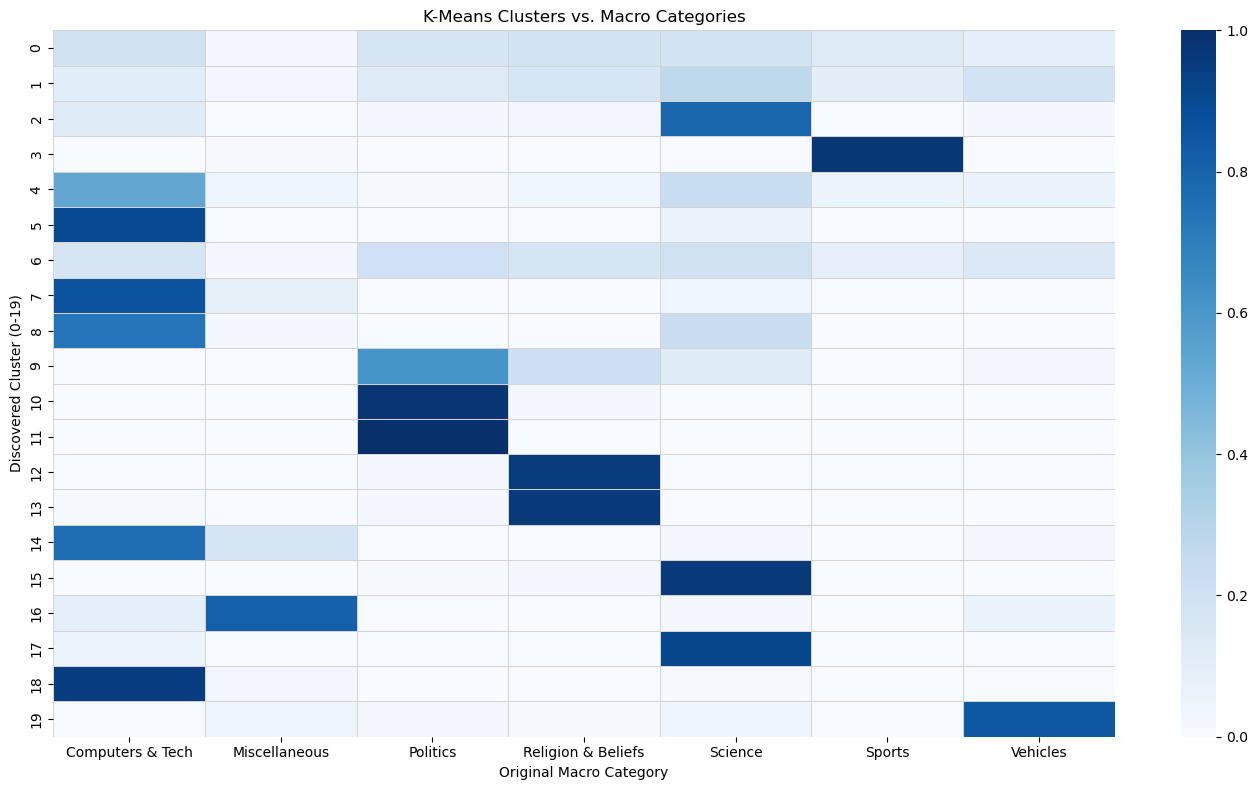

In [30]:
crosstab_macro = pd.crosstab(df['cluster'], df['macro_category'], normalize='index')

plt.figure(figsize=(14, 8))
sns.heatmap(crosstab_macro, cmap="Blues", annot=False, linewidths=0.5, linecolor='lightgray')
plt.title("K-Means Clusters vs. Macro Categories")
plt.ylabel("Discovered Cluster (0-19)")
plt.xlabel("Original Macro Category")
plt.tight_layout()
plt.show()

The visualization shows that K-Means successfully isolated some broad themes, evident in the dark, concentrated blocks in categories like `Miscellaneous`, `Sports`, and `Vehicles`. 

However, we also see distinct horizontal "smears", like clusters 0, 1, and 6, where a single cluster spans across almost every macro category. This indicates that the algorithm grouped those documents by shared conversational filler or metadata rather than actual subject matter.

**Heatmap 2: Specific Topics**

This heatmap zooms in to compare our 20 clusters directly against the 20 specific topics.

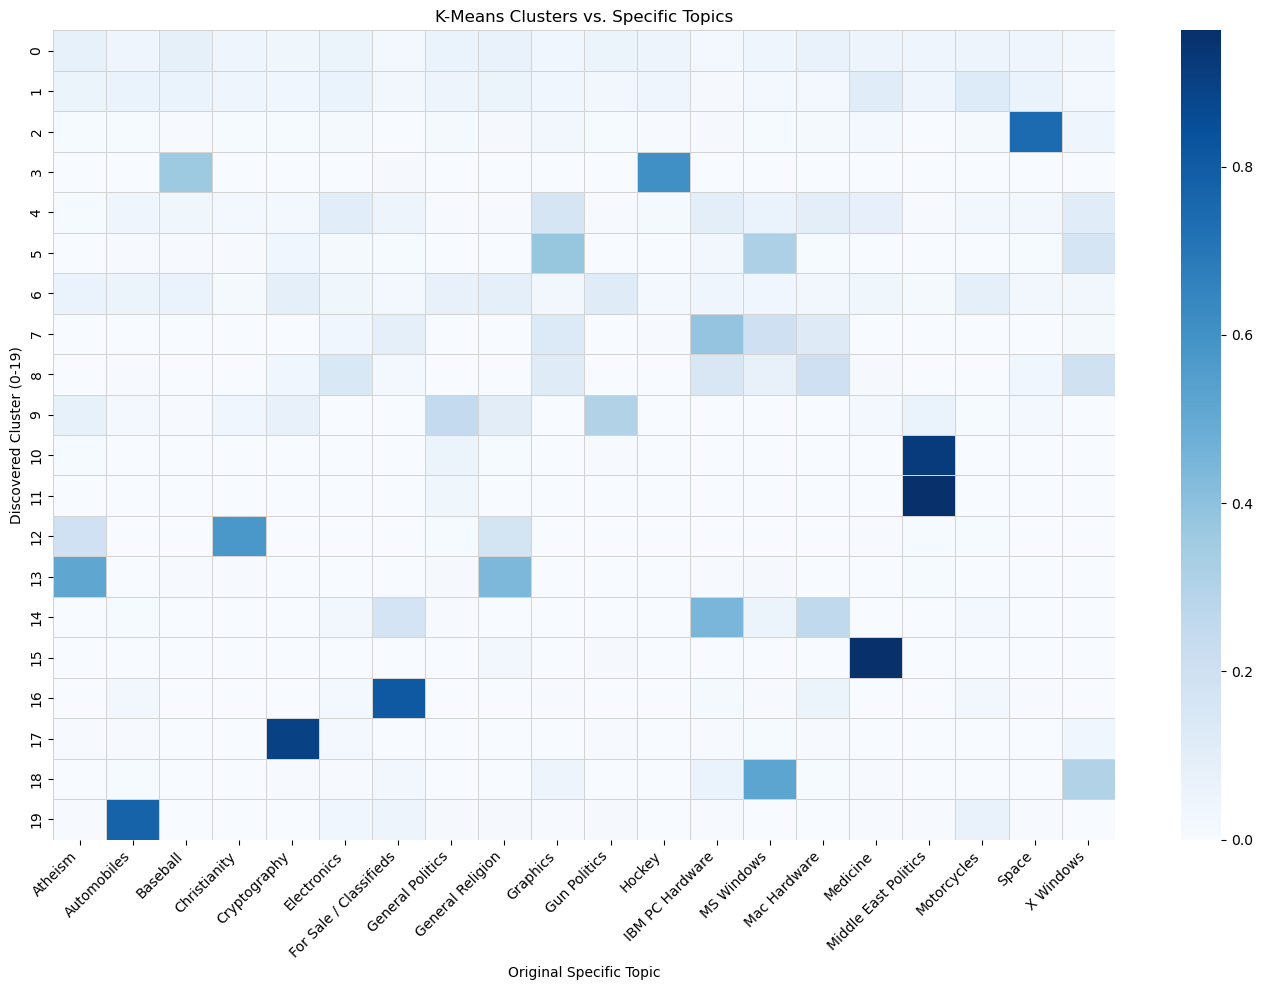

In [31]:
crosstab_topic = pd.crosstab(df['cluster'], df['topic'], normalize='index')

plt.figure(figsize=(14, 10))
sns.heatmap(crosstab_topic, cmap="Blues", annot=False, linewidths=0.5, linecolor='lightgray')
plt.title("K-Means Clusters vs. Specific Topics")
plt.ylabel("Discovered Cluster (0-19)")
plt.xlabel("Original Specific Topic")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Discussion

**1. The Successes**
K-Means succeeds when a topic has a highly specific, non-overlapping lexicon. This is shown by the dark, isolated squares in the normalized heatmap:

* **Cluster 19 (Automobiles):** Perfectly aligns with the auto group using terms like *car, engine, dealer, and mile*.
* **Cluster 17 (Cryptography):** Isolates encryption discussions with terms like *key, chip, clipper, and escrow*.
* **Cluster 16 (For Sale / Classifieds):** Groups transactional posts using terms like *sale, offer, shipping, and price*.

**2. Algorithmic Artifacts & Sub-Topic Splitting**
Because K-Means measures mathematical distance rather than human intent, it occasionally groups documents in ways a human moderator never would:

* **The Dominant Personality Artifact:** Notice how Cluster 15 maps heavily to `Medicine`. Extracting the top terms ("geb", "gordon", "banks", "chastity") reveals a fascinating Usenet artifact. Gordon Banks was a prolific contributor to the medical board. K-Means found his personal signature and vocabulary so mathematically dense that it carved out an entire cluster just for him.
* **Sub-Topic Splitting:** Look at the `Middle East Politics` column. It is represented by two dark, distinct clusters: 10 and 11. Cross-referencing our top terms reveals that Cluster 10 captures the Israel/Arab discussion, while Cluster 11 captures the Armenian/Turkish discussion. Unsupervised clustering actually subdivided the human category because it detected two distinct geopolitical vocabularies occurring within the same newsgroup.

**3. The Shared Vocabulary Trap**
When domains conceptually overlap, K-Means is no better than Naive Bayes at drawing boundaries.

* **Theology:** Instead of isolating one topic, Cluster 12 forms moderate blue blocks across both `Atheism` and `Christianity`. Lexical algorithms group by shared jargon (*god, jesus, bible*), ignoring the human intent that separates these communities.
* **Sports:** Cluster 03 similarly spans both Baseball and Hockey.
* **The Tech Shatter:** The columns for IBM PC Hardware, Mac Hardware, MS Windows, and X Windows do not map cleanly to single clusters. Instead, they appear as a checkerboard of lighter blue squares spread across clusters 05, 07, 08, 14, and 18. This visually demonstrates how broad human categories get shattered into cross-category sub-topics (like video cards or disk drives) by K-Means.

**4. The Background Noise**
The conversational "filler" and metadata clusters (00, 01, 04, 06) appear as very faint horizontal bands stretching across almost the entire x-axis. This confirms they are generic noise pulling equally from all 20 specific topics.

## Conclusion

Supervised learning attempts to force text into predefined, human-made boxes by mapping features to historical labels. It is computationally fast, scales beautifully to large datasets, and is highly effective when categories possess distinct, specialized lexicons (e.g., isolating `Medicine` from `Hockey`). It serves as an excellent, interpretable baseline for text classification.
However, the "naive" assumption treats documents as a simple bag-of-words, completely ignoring word order, tone, and context. Because it relies purely on word frequencies, it struggles heavily with overlapping vocabularies. It cannot distinguish between the underlying intent of conceptually adjacent categories (e.g., an atheistic critique versus a theological debate), routinely confusing them if they share a root vocabulary.

Unsupervised clustering ignores human-defined labels and instead reveals the mathematical and structural patterns within the text. It excels at uncovering hidden structures that human labels miss. It can successfully identify distinct sub-topics occurring within a single category (e.g., isolating the Israel/Arab and Armenian/Turkish debates) and easily isolates dominant conversational artifacts or prolific users. However, because K-Means relies on hard, lexical distance, it groups documents by *how* people write rather than *what* they mean. This makes it highly vulnerable to conversational filler and metadata. It applies hard boundaries that cause broad human topics (like General Tech) to shatter into fragmented clusters based on specific words, rather than semantic meaning.

The contrast between these two methods highlights that NLP models are ultimately only as intelligent as the features they receive. A TF-IDF matrix cannot magically infer context if the input text is saturated with structural noise. To achieve cleaner topical clusters and more accurate classifications in the future, deeper preprocessing is required before vectorization. Additionally, implementing aggressive custom stopword filtering, capturing multi-word phrases (n-grams), and utilizing Named Entity Recognition (NER) to strip out specific usernames and signatures would significantly help models isolate the true semantic signal from the surrounding conversational noise.

# More improvements to consider

To elevate this analysis, consider adding the following steps:

- Include N-grams: Update the `TfidfVectorizer` with `ngram_range=(1, 2)` or `(1, 3)` to capture bi-grams and tri-grams (e.g., "operating system" or "middle east"). This provides immediate, lightweight contextual improvements over pure unigrams.

- Implement Advanced Models: Train a Support Vector Machine (SVM) or a Logistic Regression model on the TF-IDF data. These often outperform Naive Bayes on high-dimensional text data and are better at handling overlapping feature spaces.
 
- Evaluate Cluster Quality: Add a silhouette score calculation or an elbow plot to mathematically evaluate the cohesion of the K-Means clusters and determine the true optimal `k` value.

- Visualize the Clusters: Use a dimensionality reduction technique like UMAP, t-SNE, or PCA to project the TF-IDF matrix into 2D space. Plotting these points and coloring them by their true newsgroup label provides a powerful visual representation of the overlaps and isolated islands in your dataset.

- Explore Contextual Embeddings: To solve the "Shared Vocabulary Trap," process a sample of the text through a pre-trained transformer model (like a lightweight BERT) to generate context-aware embeddings, which can differentiate between the theological use of "God" and an atheistic critique.

- Add a tree-based model like XGBoost, apply SHAP values to extract exactly which words positively or negatively drive the predictions.